# StateEstimation 逐步残差 → v / a / yaw_vel_rad 有效噪声

**Kernel：** `pixel-racers`

数据：`c0_.../extracted/state_estimation.csv`（同一消息内的位姿与 v/a）。

对相邻 SE 步，用 `(x,y,z,yaw)` 的有限差分构造参考量，与消息中的 `(vx,vy,vz)`、`(ax,ay,az)`、`yaw_vel_rad` 做残差，估计有效噪声（样本协方差 / 按 dt 归一的 Q）。

**约定**
- `base_link`：x 前、y 左、z 上；`vx,vy,vz` / `ax,ay,az` 为车体系。
- 位姿差分先在 `map` 得速度，再旋到车体与 `vx,vy` 对齐。
- `yaw_vel_rad` 与 `yaw` 高度一致（**不是** `wz`）；本 notebook 按字段名对其相对 `yaw` 估噪声，并附 `wz` vs d(yaw)/dt 对照。

> 注意：参考量与被估量来自同一 SE 消息，估的是**字段间一致性/有效过程噪声**，不是独立传感器标定。

In [ ]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "state-error-estimation":
    ROOT = ROOT.parent
OUT_DIR = ROOT / "state-error-estimation"
SE_CSV = ROOT.parent / "c0_2026-10-13_22-53-42_camloc" / "extracted" / "state_estimation.csv"

# 可选：只分析某一圈；None = 全行程
LAP_JSON = ROOT / "lapdata" / "laps.json"
LAP_FILTER: int | None = None  # e.g. 2

DT_MIN, DT_MAX = 1e-3, 0.05  # s，丢掉异常间隔
V_MIN_MOVING = 1.0  # m/s，静止段可选剔除（加速度估计）

print("SE_CSV:", SE_CSV, "exists=", SE_CSV.is_file())

## 1. 加载 SE（ns 用字符串→int64，避免 float 丢精度）

In [ ]:
def read_se_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, dtype={"timestamp_ns": str})
    df["timestamp_ns"] = df["timestamp_ns"].astype("int64")
    return df


se = read_se_csv(SE_CSV)
print("rows", len(se), "cols", list(se.columns))

if LAP_FILTER is not None:
    import json

    with open(LAP_JSON) as f:
        laps = json.load(f)["laps"]
    lap = next(L for L in laps if L["lap"] == LAP_FILTER)
    t0, t1 = int(lap["start_ns"]), int(lap["end_ns"])
    se = se[(se["timestamp_ns"] >= t0) & (se["timestamp_ns"] <= t1)].reset_index(drop=True)
    print(f"filtered lap {LAP_FILTER}: [{t0}, {t1}] -> {len(se)} rows")
else:
    print("using full recording")

## 2. 由位姿构造逐步参考量

- 速度（map）：`dp/dt`，再 `v_b = R(yaw)^T v_w`
- 加速度（车体）：对 `v_b` 再差分 `dv_b/dt`
- yaw 参考：消息内的 `yaw`（与 `yaw_vel_rad` 同量纲）
- 附：`d(yaw)/dt` 对照 `wz_radps`

In [ ]:
ts = se["timestamp_ns"].to_numpy(dtype=np.int64)
dt = np.diff(ts.astype(np.float64)) * 1e-9
valid_dt = (dt > DT_MIN) & (dt < DT_MAX)

x = se["x"].to_numpy(np.float64)
y = se["y"].to_numpy(np.float64)
z = se["z"].to_numpy(np.float64)
yaw = se["yaw"].to_numpy(np.float64)

vx_w = np.diff(x) / dt
vy_w = np.diff(y) / dt
vz_w = np.diff(z) / dt

yaw_i = yaw[:-1]
c, s = np.cos(yaw_i), np.sin(yaw_i)
# v_w = R v_b, R=[[c,-s],[s,c]] => v_b = R^T v_w
vx_pose_b = c * vx_w + s * vy_w
vy_pose_b = -s * vx_w + c * vy_w
vz_pose_b = vz_w  # z 近似与 map 上轴一致

vx_se = se["vx_mps"].to_numpy(np.float64)[:-1]
vy_se = se["vy_mps"].to_numpy(np.float64)[:-1]
vz_se = se["vz_mps"].to_numpy(np.float64)[:-1]
v_se = se["v_mps"].to_numpy(np.float64)[:-1]

r_vx = vx_se - vx_pose_b
r_vy = vy_se - vy_pose_b
r_vz = vz_se - vz_pose_b
r_v_norm = v_se - np.hypot(vx_pose_b, vy_pose_b)

# 加速度：对 pose 导出的车体速度再差分；SE a 取区间中点索引
dt2 = dt[:-1]
valid_dt2 = valid_dt[:-1] & valid_dt[1:]
ax_pose = np.diff(vx_pose_b) / dt2
ay_pose = np.diff(vy_pose_b) / dt2
az_pose = np.diff(vz_pose_b) / dt2
ax_se = se["ax_mps2"].to_numpy(np.float64)[1:-1]
ay_se = se["ay_mps2"].to_numpy(np.float64)[1:-1]
az_se = se["az_mps2"].to_numpy(np.float64)[1:-1]
r_ax = ax_se - ax_pose
r_ay = ay_se - ay_pose
r_az = az_se - az_pose

# yaw_vel_rad vs yaw（同量纲）
yaw_vel = se["yaw_vel_rad"].to_numpy(np.float64)[:-1]
r_yaw_vel = yaw_vel - yaw_i
r_yaw_vel = (r_yaw_vel + np.pi) % (2 * np.pi) - np.pi

# 对照：wz vs d(yaw)/dt
dyaw = np.diff(np.unwrap(yaw)) / dt
wz = se["wz_radps"].to_numpy(np.float64)[:-1]
r_wz = wz - dyaw

print(f"steps: v={valid_dt.sum()}/{len(dt)}  a={valid_dt2.sum()}/{len(dt2)}")
print(
    "sanity |yaw_vel-yaw| median rad/deg:",
    float(np.median(np.abs(r_yaw_vel[valid_dt]))),
    float(np.median(np.abs(r_yaw_vel[valid_dt])) * 180 / np.pi),
)
print(
    "sanity |wz-dpsi| median rad/s:",
    float(np.median(np.abs(r_wz[valid_dt]))),
)

## 3. 噪声统计工具

对残差 r：
- 样本协方差 `R = Cov(r)`
- 若假设 `Var(r) ≈ Q·dt`：`Q ≈ mean(r r^T / dt)`
- 若假设 `Var(r) ≈ Q·dt²`：`Q ≈ mean(r r^T / dt²)`

速度残差已是速度量，故对 v 直接报 `Cov(r_v)`（单位 m²/s²），并可选把一步位移噪声写成 `Q_dp = mean((r_v·dt)(r_v·dt)^T / dt)`。

In [ ]:
def cov_matrix(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=np.float64)
    if X.ndim == 1:
        X = X[:, None]
    X = X - X.mean(axis=0, keepdims=True)
    n = X.shape[0]
    if n < 2:
        return np.full((X.shape[1], X.shape[1]), np.nan)
    return (X.T @ X) / (n - 1)


def summarize_residuals(
    name: str,
    R: np.ndarray,
    dt_s: np.ndarray,
    labels: list[str],
) -> dict:
    """R: (N,d) residuals at steps with dt_s (N,)."""
    R = np.asarray(R, dtype=np.float64)
    if R.ndim == 1:
        R = R[:, None]
    dt_s = np.asarray(dt_s, dtype=np.float64)
    assert len(R) == len(dt_s)

    med = np.median(R, axis=0)
    mad = np.median(np.abs(R - med), axis=0) * 1.4826  # ~sigma
    rms = np.sqrt(np.mean(R**2, axis=0))
    C = cov_matrix(R)

    Q_dt = np.mean(
        np.einsum("ni,nj->nij", R, R) / dt_s[:, None, None], axis=0
    )
    Q_dt2 = np.mean(
        np.einsum("ni,nj->nij", R, R) / (dt_s**2)[:, None, None], axis=0
    )

    return {
        "name": name,
        "n": int(len(R)),
        "labels": labels,
        "mean": R.mean(axis=0),
        "median": med,
        "rms": rms,
        "mad_sigma": mad,
        "cov": C,
        "Q_per_dt": Q_dt,
        "Q_per_dt2": Q_dt2,
        "std": np.sqrt(np.diag(C)),
    }


def print_summary(s: dict) -> None:
    print(f"\n=== {s['name']}  n={s['n']} ===")
    for i, lab in enumerate(s["labels"]):
        print(
            f"  {lab:10s}  mean={s['mean'][i]:+.4e}  rms={s['rms'][i]:.4e}  "
            f"madσ={s['mad_sigma'][i]:.4e}  std={s['std'][i]:.4e}"
        )
    with np.printoptions(precision=4, suppress=True, linewidth=120):
        print("  Cov:\n", s["cov"])
        print("  Q (Var≈Q·Δt):\n", s["Q_per_dt"])
        print("  Q (Var≈Q·Δt²):\n", s["Q_per_dt2"])

## 4. 估计 Q_v, Q_a, Q_yaw_vel

In [ ]:
mask_v = valid_dt
Rv = np.column_stack([r_vx[mask_v], r_vy[mask_v], r_vz[mask_v]])
sum_v = summarize_residuals("velocity (SE - pose FD), body", Rv, dt[mask_v], ["vx", "vy", "vz"])
print_summary(sum_v)

sum_v_scalar = summarize_residuals(
    "v_mps (SE - |v_pose_xy|)",
    r_v_norm[mask_v],
    dt[mask_v],
    ["v"],
)
print_summary(sum_v_scalar)

v_mid = v_se[1:]
mask_a = valid_dt2 & (v_mid > V_MIN_MOVING)
Ra = np.column_stack([r_ax[mask_a], r_ay[mask_a], r_az[mask_a]])
sum_a = summarize_residuals(
    f"acceleration (SE - d(v_pose)/dt), body, |v|>{V_MIN_MOVING}",
    Ra,
    dt2[mask_a],
    ["ax", "ay", "az"],
)
print_summary(sum_a)

sum_yaw_vel = summarize_residuals(
    "yaw_vel_rad - yaw  [rad]",
    r_yaw_vel[mask_v],
    dt[mask_v],
    ["yaw_vel"],
)
print_summary(sum_yaw_vel)

sum_wz = summarize_residuals(
    "wz_radps - d(yaw)/dt  [rad/s]  (对照, 非 yaw_vel)",
    r_wz[mask_v],
    dt[mask_v],
    ["wz"],
)
print_summary(sum_wz)

r_dp = Rv * dt[mask_v][:, None]
Q_dp_dt = np.mean(np.einsum("ni,nj->nij", r_dp, r_dp) / dt[mask_v][:, None, None], axis=0)
print("\n=== derived Q_Δp with Var(Δp)≈Q_Δp·Δt  (from r_v·Δt) ===")
with np.printoptions(precision=6, suppress=True):
    print(Q_dp_dt)

## 5. 残差分布 vs 拟合高斯

对每个残差分量画 **密度直方图**，并叠加两条高斯：
- `N(mean, std)`：矩匹配（受离群点影响大）
- `N(median, MADσ)`：稳健匹配（`MADσ = 1.4826·MAD`）

若直方图明显比红线更尖、比橙线更胖，说明重尾，不宜只用 std 高斯。

saved /Users/hbai/SchubKI/PixelRacers/state-error-estimation/se_step_residuals_vs_gaussian.png


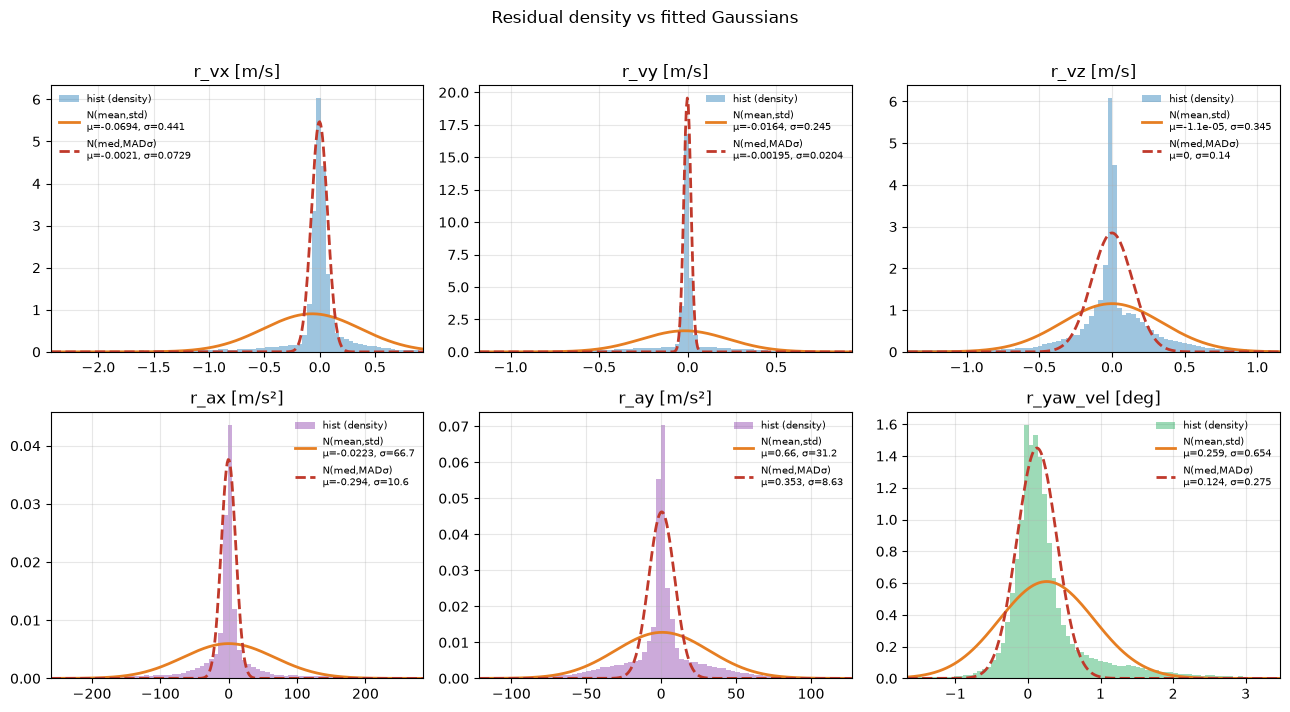

,residual,mean,std,median,mad_sigma,n
0,r_vx [m/s],-0.069396,0.440683,-0.002101,0.072916,126572
1,r_vy [m/s],-0.016368,0.245229,-0.001950,0.020390,126572
2,r_vz [m/s],-0.000011,0.345096,0.000000,0.139998,126572
3,r_ax [m/s²],-0.022338,66.695594,-0.294361,10.591459,124847
4,r_ay [m/s²],0.659835,31.198813,0.352876,8.625174,124847
5,r_yaw_vel [deg],0.259496,0.654145,0.124332,0.275015,126572


In [8]:
def gaussian_pdf(x: np.ndarray, mu: float, sigma: float) -> np.ndarray:
    sigma = max(float(sigma), 1e-12)
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))


def plot_hist_vs_gaussian(
    ax,
    data: np.ndarray,
    *,
    title: str,
    color: str = "#2980b9",
    bins: int = 80,
    clip_pct: tuple[float, float] = (0.5, 99.5),
) -> dict:
    """Density hist + N(mean,std) + N(median,MADσ). Returns fit stats."""
    data = np.asarray(data, dtype=np.float64)
    data = data[np.isfinite(data)]
    lo, hi = np.percentile(data, clip_pct)
    # 画图用截尾范围，拟合参数仍用全部样本（与第4节一致）
    mu = float(np.mean(data))
    sigma = float(np.std(data, ddof=1))
    med = float(np.median(data))
    mad_sigma = float(np.median(np.abs(data - med)) * 1.4826)

    vis = data[(data >= lo) & (data <= hi)]
    counts, edges, _ = ax.hist(
        vis,
        bins=bins,
        density=True,
        color=color,
        alpha=0.45,
        edgecolor="none",
        label="hist (density)",
    )
    xs = np.linspace(lo, hi, 400)
    ax.plot(
        xs,
        gaussian_pdf(xs, mu, sigma),
        color="#e67e22",
        lw=2.0,
        label=f"N(mean,std)\nμ={mu:.3g}, σ={sigma:.3g}",
    )
    ax.plot(
        xs,
        gaussian_pdf(xs, med, mad_sigma),
        color="#c0392b",
        lw=2.0,
        ls="--",
        label=f"N(med,MADσ)\nμ={med:.3g}, σ={mad_sigma:.3g}",
    )
    ax.set_title(title)
    ax.set_xlim(lo, hi)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="best", frameon=False)
    return {"mean": mu, "std": sigma, "median": med, "mad_sigma": mad_sigma, "n": int(len(data))}


panel = [
    (r_vx[mask_v], "r_vx [m/s]", "#2980b9"),
    (r_vy[mask_v], "r_vy [m/s]", "#2980b9"),
    (r_vz[mask_v], "r_vz [m/s]", "#2980b9"),
    (r_ax[mask_a], "r_ax [m/s²]", "#8e44ad"),
    (r_ay[mask_a], "r_ay [m/s²]", "#8e44ad"),
    (r_yaw_vel[mask_v] * 180 / np.pi, "r_yaw_vel [deg]", "#27ae60"),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
fit_rows = []
for ax, (data, title, color) in zip(axes.ravel(), panel):
    stats = plot_hist_vs_gaussian(ax, data, title=title, color=color)
    fit_rows.append({"residual": title, **stats})

fig.suptitle("Residual density vs fitted Gaussians", y=1.01)
fig.tight_layout()
fig_path = OUT_DIR / "se_step_residuals_vs_gaussian.png"
fig.savefig(fig_path, dpi=140, bbox_inches="tight")
print("saved", fig_path)
plt.show()

pd.DataFrame(fit_rows)

### QQ 图（相对 N(mean, std)）

点落在对角线上 ≈ 高斯；两端偏离 = 重尾/轻尾。

In [ ]:
from scipy import stats as sp_stats


def qq_against_gaussian(ax, data: np.ndarray, title: str, color: str) -> None:
    data = np.asarray(data, dtype=np.float64)
    data = data[np.isfinite(data)]
    # 子采样加速；保持分布形状
    if len(data) > 20000:
        rng = np.random.default_rng(0)
        data = rng.choice(data, size=20000, replace=False)
    mu = float(np.mean(data))
    sigma = max(float(np.std(data, ddof=1)), 1e-12)
    sp_stats.probplot(data, dist=sp_stats.norm(loc=mu, scale=sigma), plot=ax)
    ax.get_lines()[0].set_markerfacecolor(color)
    ax.get_lines()[0].set_markeredgecolor(color)
    ax.get_lines()[0].set_markersize(2.5)
    ax.get_lines()[0].set_alpha(0.35)
    ax.get_lines()[1].set_color("#e74c3c")
    ax.get_lines()[1].set_linewidth(1.5)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (data, title, color) in zip(axes.ravel(), panel):
    qq_against_gaussian(ax, data, title=title, color=color)

fig.suptitle("QQ vs N(mean, std)", y=1.01)
fig.tight_layout()
qq_path = OUT_DIR / "se_step_residuals_qq.png"
fig.savefig(qq_path, dpi=140, bbox_inches="tight")
print("saved", qq_path)
plt.show()

## 6. 导出噪声模型摘要

In [ ]:
def pack(s: dict) -> dict:
    return {
        "name": s["name"],
        "n": s["n"],
        "labels": s["labels"],
        "mean": s["mean"].tolist(),
        "rms": s["rms"].tolist(),
        "mad_sigma": s["mad_sigma"].tolist(),
        "std": s["std"].tolist(),
        "cov": s["cov"].tolist(),
        "Q_Var_eq_Q_dt": s["Q_per_dt"].tolist(),
        "Q_Var_eq_Q_dt2": s["Q_per_dt2"].tolist(),
    }


import json

model = {
    "source": str(SE_CSV),
    "lap_filter": LAP_FILTER,
    "dt_gate_s": [DT_MIN, DT_MAX],
    "v_min_moving_mps": V_MIN_MOVING,
    "note": (
        "Residuals are SE reported fields minus finite-difference references "
        "from the same message pose (x,y,z,yaw). yaw_vel_rad is compared to yaw "
        "(same units); wz vs d(yaw)/dt is provided as angular-rate reference."
    ),
    "velocity_body": pack(sum_v),
    "v_mps": pack(sum_v_scalar),
    "acceleration_body": pack(sum_a),
    "yaw_vel_rad_minus_yaw": pack(sum_yaw_vel),
    "wz_minus_dyaw": pack(sum_wz),
    "Q_delta_p_Var_eq_Q_dt": Q_dp_dt.tolist(),
}

out_json = OUT_DIR / "se_step_residual_noise.json"
out_json.write_text(json.dumps(model, indent=2) + "\n", encoding="utf-8")
print("wrote", out_json)

rows = []
for s in (sum_v, sum_v_scalar, sum_a, sum_yaw_vel, sum_wz):
    for i, lab in enumerate(s["labels"]):
        rows.append(
            {
                "group": s["name"],
                "component": lab,
                "n": s["n"],
                "mean": s["mean"][i],
                "rms": s["rms"][i],
                "std": s["std"][i],
                "mad_sigma": s["mad_sigma"][i],
                "Q_diag_per_dt": float(s["Q_per_dt"][i, i]),
                "Q_diag_per_dt2": float(s["Q_per_dt2"][i, i]),
            }
        )
summary_csv = OUT_DIR / "se_step_residual_noise_summary.csv"
pd.DataFrame(rows).to_csv(summary_csv, index=False)
print("wrote", summary_csv)
pd.DataFrame(rows)

## 7. 如何把结果填进滤波器

| 量 | 建议使用的矩阵 | 单位（Var≈Q·dt 时） |
|----|----------------|---------------------|
| 速度过程/测量 | `velocity_body.cov` 或 `Q_Var_eq_Q_dt` | m²/s² 或 m²/s |
| 加速度 | `acceleration_body.cov` | m²/s⁴（cov） |
| `yaw_vel_rad` 当航向观测 | `yaw_vel_rad_minus_yaw.cov` | rad² |
| 若要用角速度 | 用 `wz_minus_dyaw`，**不要**用 `yaw_vel_rad` | rad²/s² |

二次差分使 a 残差偏大；运动段 + MADσ 比 RMS 更稳。需要按圈估计时设 `LAP_FILTER = 2` 后重跑。